# Nuclei segmentation, end to end

A small image segmentation pipeline on public microscopy data, built to show each step of a real project.

It covers dataset preparation, annotation and quality control, transfer learning, model evaluation and optimization, and web-based deployment for online inference.

**Data:** 670 microscope images of cell nuclei, each nucleus outlined by hand. From the 2018 Data Science Bowl, Broad Bioimage Benchmark Collection (BBBC038v1), public domain (CC0). Caicedo et al., *Nature Methods* 16, 1247-1253 (2019).

| Step | Section |
|---|---|
| Dataset preparation | 1 |
| Annotation and quality control | 2, and 5 after training |
| Transfer learning | 3 |
| Model evaluation | 4 |
| Optimization | 6 |
| Web-based deployment, online inference | 7 |

In [1]:
import json
import os
import time
from pathlib import Path

os.environ.setdefault("GRADIO_ANALYTICS_ENABLED", "False")

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import segmentation_models_pytorch as smp
import torch
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy import ndimage as ndi

from inference import draw_nuclei, draw_outlines, for_display, normalize, predict_prob_onnx, preprocess, split_nuclei

DATA = Path("data/stage1_train")
MODELS = Path("models")
MODELS.mkdir(exist_ok=True)
RETRAIN = False  # True trains both models again, about 30 minutes on an Apple M4
EPOCHS, BATCH, CROP = 20, 16, 256
SEED = 0
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")

# Chart style: light surface, quiet grid, color-blind-safe colors.
# Aqua = hand-drawn masks, orange = the model, blue = missed by the model.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
rgb_of = lambda hex_color: tuple(int(hex_color[k:k + 2], 16) for k in (1, 3, 5))
TYPE_COLORS = {"fluorescent": BLUE, "stained tissue": ORANGE, "brightfield": AQUA}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 10,
    "axes.titlelocation": "left", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "font.size": 10, "figure.dpi": 110,
})
print("Training device:", device)

Training device: mps


## 1. Dataset preparation

Each image comes with one mask file per nucleus. I merge them into one label image per picture, which keeps every nucleus separate for counting later. I also sort the pictures into three types by color, because the model has to work on all three.

In [2]:
def load_sample(sample_id):
    image = cv2.imread(str(DATA / sample_id / "images" / f"{sample_id}.png"), cv2.IMREAD_COLOR)[..., ::-1].copy()
    label_map = np.zeros(image.shape[:2], np.uint16)
    stats, holes = [], []
    for k, path in enumerate(sorted((DATA / sample_id / "masks").glob("*.png")), start=1):
        mask = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE) > 0
        x, y, w, h = cv2.boundingRect(mask.astype(np.uint8))
        box = np.s_[max(y - 1, 0):y + h + 1, max(x - 1, 0):x + w + 1]
        m = mask[box]
        n_parts, parts = cv2.connectedComponents(m.astype(np.uint8), connectivity=8)
        part_sizes = np.sort(np.bincount(parts.ravel())[1:])[::-1]
        hole = ndi.binary_fill_holes(m) & ~m
        region = label_map[box]
        stats.append({
            "id": sample_id,
            "mask": path.stem,
            "label": k,
            "area": int(m.sum()),
            "pieces": n_parts - 1,
            "second_piece_px": int(part_sizes[1]) if len(part_sizes) > 1 else 0,
            "hole_px": int(hole.sum()),
            "overlap_px": int((m & (region > 0)).sum()),
        })
        region[m & (region == 0)] = k
        holes.append((box, hole, k))
    for box, hole, k in holes:  # holes are filled last, and only where no other nucleus sits (see section 2)
        region = label_map[box]
        region[hole & (region == 0)] = k
    return image, label_map, stats


t0 = time.time()
ids = sorted(p.name for p in DATA.iterdir() if p.is_dir())
images, label_maps, mask_rows = {}, {}, []
for sample_id in ids:
    images[sample_id], label_maps[sample_id], stats = load_sample(sample_id)
    mask_rows += stats
masks_df = pd.DataFrame(mask_rows)
binary = {i: label_maps[i] > 0 for i in ids}
print(f"{len(ids)} images, {len(masks_df):,} nuclei, loaded in {time.time() - t0:.0f} s")

670 images, 29,461 nuclei, loaded in 14 s


In [3]:
def image_type(image):
    rgb = image.astype(np.int16)
    color = np.abs(rgb[..., 0] - rgb[..., 1]).mean() + np.abs(rgb[..., 1] - rgb[..., 2]).mean()
    if color > 8:
        return "stained tissue"
    return "fluorescent" if image.mean() < 100 else "brightfield"


TYPES = ["fluorescent", "stained tissue", "brightfield"]
meta = pd.DataFrame({"id": ids})
meta["type"] = [image_type(images[i]) for i in ids]
meta["size"] = [f"{images[i].shape[0]} x {images[i].shape[1]}" for i in ids]
meta["nuclei"] = meta.id.map(masks_df.groupby("id").size())
type_of = meta.set_index("id").type
nuclei_of = meta.set_index("id").nuclei

meta.groupby("type").agg(
    images=("id", "size"),
    nuclei=("nuclei", "sum"),
    median_nuclei_per_image=("nuclei", "median"),
    most_common_size=("size", lambda s: s.mode()[0]),
).reindex(TYPES)

,images,nuclei,median_nuclei_per_image,most_common_size
type,,,,
fluorescent,546,23541,25.0,256 x 256
stained tissue,108,4575,32.5,256 x 320
brightfield,16,1345,80.5,1024 x 1024


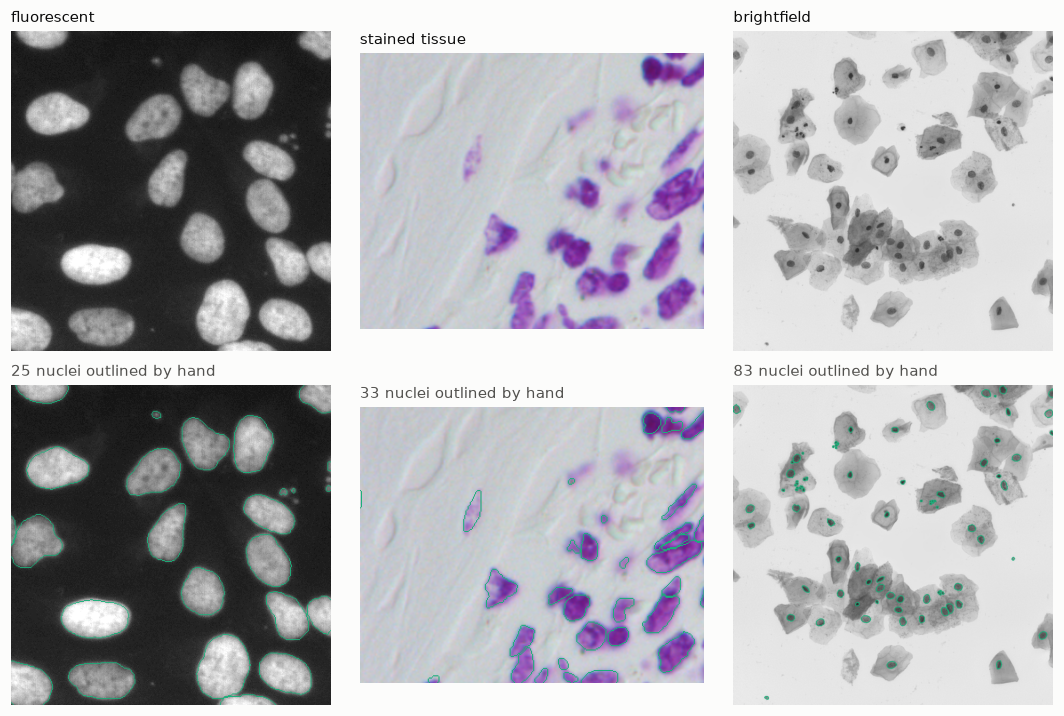

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6.6))
for col, t in enumerate(TYPES):
    of_type = meta[meta.type == t].sort_values("nuclei")
    sample_id = of_type.id.iloc[len(of_type) // 2]  # a typical image of this type
    axes[0, col].imshow(for_display(images[sample_id]))
    axes[0, col].set_title(t)
    axes[1, col].imshow(draw_outlines(for_display(images[sample_id]), label_maps[sample_id], color=rgb_of(AQUA)))
    axes[1, col].set_title(f"{nuclei_of[sample_id]} nuclei outlined by hand", color=INK2)
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

Dark fluorescent images are brightened in the figures for viewing only. The model sees the original pixels.

The split keeps the same mix of types in each part. The test images are used once, at the end of section 4.

In [5]:
rng = np.random.default_rng(SEED)
meta["split"] = "train"
for t, group in meta.groupby("type"):
    shuffled = rng.permutation(group.index.to_numpy())
    n = round(0.15 * len(shuffled))
    meta.loc[shuffled[:n], "split"] = "test"
    meta.loc[shuffled[n:2 * n], "split"] = "val"
train_ids, val_ids, test_ids = (meta.id[meta.split == s].tolist() for s in ("train", "val", "test"))

pd.crosstab(meta.type, meta.split, margins=True, margins_name="total").reindex(TYPES + ["total"])[["train", "val", "test", "total"]]

split,train,val,test,total
type,,,,
fluorescent,382,82,82,546
stained tissue,76,16,16,108
brightfield,12,2,2,16
total,470,100,100,670


## 2. Annotation quality control

A model learns whatever the masks say, mistakes included, so I check the labels before training. These checks need no model, only the masks.

In [6]:
def dhash(image, size=16):
    gray = cv2.resize(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY), (size + 1, size), interpolation=cv2.INTER_AREA)
    return (gray[:, 1:] > gray[:, :-1]).ravel()


hashes = np.stack([dhash(images[i]) for i in ids])
hash_distance = (hashes[:, None, :] != hashes[None, :, :]).sum(-1)
near_duplicate_pairs = int(np.triu(hash_distance <= 10, k=1).sum())

masks_df["median_area_in_image"] = masks_df.groupby("id").area.transform("median")
masks_df["masks_in_image"] = masks_df.groupby("id").area.transform("size")
checks = {
    "Mask broken into separate pieces": masks_df.pieces > 1,
    "Mask with a hole inside": masks_df.hole_px > 0,
    "Mask over 6x the median size in its image (possibly merged nuclei)":
        (masks_df.area > 6 * masks_df.median_area_in_image) & (masks_df.masks_in_image >= 5),
    "Masks overlapping each other": masks_df.overlap_px > 0,
}
qc = pd.DataFrame([{"check": name, "masks": int(hit.sum()), "images": int(masks_df.id[hit].nunique())}
                   for name, hit in checks.items()]
                  + [{"check": "Near-duplicate image pairs (would leak between train and test)",
                      "masks": "n/a", "images": near_duplicate_pairs}])
hole_sizes = masks_df.hole_px[masks_df.hole_px > 0]
print(f"Most holes are small ({hole_sizes.median():.0f} pixels at the median), but a model should not learn that a nucleus can be hollow.")
qc.set_index("check")

Most holes are small (2 pixels at the median), but a model should not learn that a nucleus can be hollow.


,masks,images
check,,
Mask broken into separate pieces,11,11
Mask with a hole inside,425,96
Mask over 6x the median size in its image (possibly merged nuclei),34,11
Masks overlapping each other,0,0
Near-duplicate image pairs (would leak between train and test),n/a,0


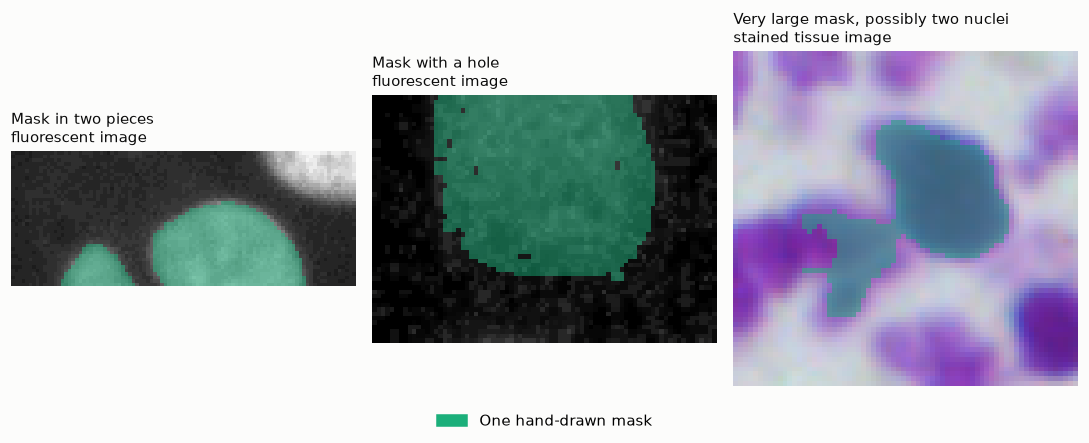

In [7]:
def crop_around(mask, margin=14):
    ys, xs = np.nonzero(mask)
    return np.s_[max(ys.min() - margin, 0):ys.max() + margin + 1, max(xs.min() - margin, 0):xs.max() + margin + 1]


def tint(image, mask, color, alpha=0.5):
    out = image.astype(np.float32).copy()
    out[mask] = (1 - alpha) * out[mask] + alpha * np.array(color, np.float32)
    return out.astype(np.uint8)


def read_mask(row):
    return cv2.imread(str(DATA / row["id"] / "masks" / f"{row['mask']}.png"), cv2.IMREAD_GRAYSCALE) > 0


def solidity(mask):
    # Area over convex-hull area: close to 1 for a round nucleus, lower for two nuclei joined together.
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contour = max(contours, key=cv2.contourArea)
    return cv2.contourArea(contour) / max(cv2.contourArea(cv2.convexHull(contour)), 1.0)


in_pieces = masks_df[checks["Mask broken into separate pieces"]]
with_hole = masks_df[checks["Mask with a hole inside"] & (masks_df.overlap_px == 0)]
large = masks_df[checks["Mask over 6x the median size in its image (possibly merged nuclei)"]].copy()
large["solidity"] = [solidity(read_mask(row)) for _, row in large.iterrows()]
examples = {
    "Mask in two pieces": in_pieces.sort_values("second_piece_px").iloc[-1],
    "Mask with a hole": with_hole.sort_values("hole_px").iloc[int(0.9 * (len(with_hole) - 1))],
    "Very large mask, possibly two nuclei": large.sort_values("solidity").iloc[0],
}
fig, axes = plt.subplots(1, 3, figsize=(10, 3.8))
for ax, (title, row) in zip(axes, examples.items()):
    mask = read_mask(row)
    ax.imshow(tint(for_display(images[row["id"]]), mask, rgb_of(AQUA))[crop_around(mask)])
    ax.set_title(f"{title}\n{type_of[row['id']]} image", color=INK)
    ax.axis("off")
fig.legend(handles=[Patch(color=AQUA, label="One hand-drawn mask")], loc="lower center")
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

What I do with each finding:

1. **Holes are filled**, since a nucleus has no hole in the middle. The same rule applies to every split, so training and scoring use the same labels (done while loading in section 1).
2. **Masks in pieces and very large masks are kept** and listed in `qc_flags.csv` for a person to check, because fixing them needs a human eye.
3. **No overlaps and no near-duplicates**, so the split in section 1 has no copies across train and test.

In [8]:
flag_hit = checks["Mask broken into separate pieces"] | checks["Mask over 6x the median size in its image (possibly merged nuclei)"]
flagged = masks_df[flag_hit].copy()
flagged["reason"] = np.where(flagged.pieces > 1, "in pieces", "very large")
flagged[["id", "mask", "reason", "area"]].to_csv("qc_flags.csv", index=False)
print(f"{len(flagged)} masks in {flagged.id.nunique()} images written to qc_flags.csv for review")

45 masks in 22 images written to qc_flags.csv for review


## 3. Transfer learning

The model is a U-Net, a standard segmentation network, with a ResNet34 encoder pretrained on ImageNet. To see what the pretraining is worth here, I train the same model twice with the same data and settings: once from the pretrained weights and once from random weights.

Training uses random 256 x 256 crops with flips and rotations, and keeps the version with the best validation score.

In [9]:
def random_crop(sample_id, rng):
    image, mask = images[sample_id], binary[sample_id]
    y = rng.integers(0, mask.shape[0] - CROP + 1)
    x = rng.integers(0, mask.shape[1] - CROP + 1)
    image, mask = image[y:y + CROP, x:x + CROP], mask[y:y + CROP, x:x + CROP]
    k = int(rng.integers(4))
    image, mask = np.rot90(image, k), np.rot90(mask, k)
    if rng.random() < 0.5:
        image, mask = image[:, ::-1], mask[:, ::-1]
    return np.ascontiguousarray(normalize(image)), mask[None].astype(np.float32)


def training_batches(rng, crops_per_image=2):
    order = rng.permutation(np.repeat(train_ids, crops_per_image))
    for start in range(0, len(order) - BATCH + 1, BATCH):
        x, y = zip(*(random_crop(i, rng) for i in order[start:start + BATCH]))
        yield torch.from_numpy(np.stack(x)), torch.from_numpy(np.stack(y))


@torch.no_grad()
def predict(model, image):
    x, (h, w) = preprocess(image)
    return torch.sigmoid(model(torch.from_numpy(x).to(device)))[0, 0, :h, :w].cpu().numpy()


def dice(pred, truth):
    total = pred.sum() + truth.sum()
    return 1.0 if total == 0 else 2 * (pred & truth).sum() / total


def iou(pred, truth):
    union = (pred | truth).sum()
    return 1.0 if union == 0 else (pred & truth).sum() / union


def new_model(pretrained):
    return smp.Unet("resnet34", encoder_weights="imagenet" if pretrained else None, classes=1)

In [10]:
def train(pretrained, name):
    torch.manual_seed(SEED)
    rng = np.random.default_rng(SEED)
    model = new_model(pretrained).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
    steps_per_epoch = len(train_ids) * 2 // BATCH
    schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * steps_per_epoch)
    dice_loss, bce_loss = smp.losses.DiceLoss("binary"), torch.nn.BCEWithLogitsLoss()
    history, best = [], -1.0
    for epoch in range(1, EPOCHS + 1):
        t0, losses = time.time(), []
        model.train()
        for x, y in training_batches(rng):
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = dice_loss(logits, y) + bce_loss(logits, y)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            schedule.step()
            losses.append(loss.item())
        model.eval()
        val_dice = float(np.mean([dice(predict(model, images[i]) > 0.5, binary[i]) for i in val_ids]))
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "val_dice": val_dice})
        if val_dice > best:
            best = val_dice
            torch.save(model.state_dict(), MODELS / f"{name}.pt")
        print(f"{name:16s} epoch {epoch:2d}   loss {np.mean(losses):.3f}   validation Dice {val_dice:.3f}   ({time.time() - t0:.0f} s)")
    (MODELS / f"{name}_history.json").write_text(json.dumps(history))
    return history


RUNS = {"unet_pretrained": ("Pretrained encoder (ImageNet)", True),
        "unet_scratch": ("Same model, random start", False)}
histories = {}
for name, (label, pretrained) in RUNS.items():
    saved = MODELS / f"{name}_history.json"
    if RETRAIN or not saved.exists():
        histories[name] = train(pretrained, name)
    else:
        histories[name] = json.loads(saved.read_text())
        print(f"{name}: loaded the saved run (set RETRAIN = True to train again)")
        for r in histories[name]:
            print(f"{name:16s} epoch {r['epoch']:2d}   loss {r['train_loss']:.3f}   validation Dice {r['val_dice']:.3f}")

after = lambda h, e: h[min(e, len(h)) - 1]["val_dice"]
pd.DataFrame({label: {"validation Dice after 1 epoch": after(histories[name], 1),
                      "after 5 epochs": after(histories[name], 5),
                      "best": max(r["val_dice"] for r in histories[name])}
              for name, (label, _) in RUNS.items()}).T.round(3)

unet_pretrained: loaded the saved run (set RETRAIN = True to train again)
unet_pretrained  epoch  1   loss 1.179   validation Dice 0.758
unet_pretrained  epoch  2   loss 0.672   validation Dice 0.891
unet_pretrained  epoch  3   loss 0.466   validation Dice 0.903
unet_pretrained  epoch  4   loss 0.350   validation Dice 0.911
unet_pretrained  epoch  5   loss 0.290   validation Dice 0.905
unet_pretrained  epoch  6   loss 0.249   validation Dice 0.916
unet_pretrained  epoch  7   loss 0.221   validation Dice 0.916
unet_pretrained  epoch  8   loss 0.208   validation Dice 0.913
unet_pretrained  epoch  9   loss 0.194   validation Dice 0.919
unet_pretrained  epoch 10   loss 0.190   validation Dice 0.910
unet_pretrained  epoch 11   loss 0.188   validation Dice 0.917
unet_pretrained  epoch 12   loss 0.178   validation Dice 0.921
unet_pretrained  epoch 13   loss 0.174   validation Dice 0.923
unet_pretrained  epoch 14   loss 0.175   validation Dice 0.921
unet_pretrained  epoch 15   loss 0.167   val

,validation Dice after 1 epoch,after 5 epochs,best
Pretrained encoder (ImageNet),0.758,0.905,0.925
"Same model, random start",0.828,0.862,0.911


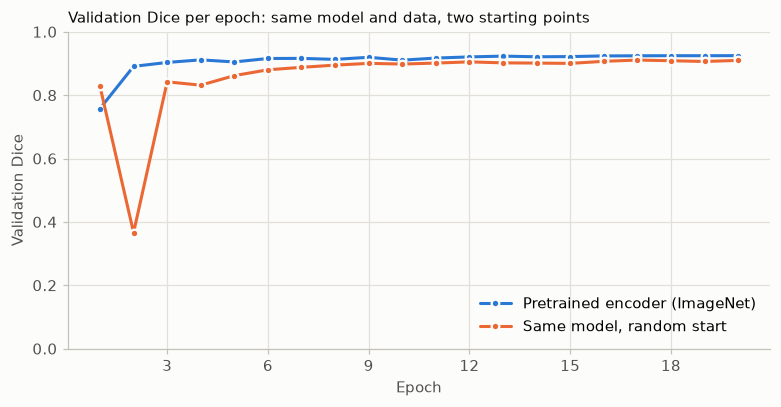

In [11]:
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for (name, (label, _)), color in zip(RUNS.items(), (BLUE, ORANGE)):
    epochs = [r["epoch"] for r in histories[name]]
    scores = [r["val_dice"] for r in histories[name]]
    ax.plot(epochs, scores, color=color, label=label, marker="o", markersize=5,
            markeredgecolor=SURFACE, markeredgewidth=1.5)
    ends = [histories[n][-1]["val_dice"] for n in RUNS]
    if abs(ends[0] - ends[1]) > 0.05:  # label the line ends only when the labels cannot collide
        ax.annotate(f"{scores[-1]:.2f}", (epochs[-1], scores[-1]), xytext=(8, 0),
                    textcoords="offset points", va="center", color=INK2)
ax.set(xlabel="Epoch", ylabel="Validation Dice", ylim=(0, 1))
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_title("Validation Dice per epoch: same model and data, two starting points")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. Model evaluation

The mask threshold is chosen on the validation images, never on the test images, so the test score stays honest. Then the test images are scored once: Dice and IoU for every image, averaged, and split by image type, because an average can hide a type that fails.

In [12]:
model = new_model(pretrained=False).to(device)
model.load_state_dict(torch.load(MODELS / "unet_pretrained.pt", map_location=device))
model.eval()
probs = {i: predict(model, images[i]) for i in val_ids + test_ids}

thresholds = [float(round(t, 2)) for t in np.arange(0.30, 0.71, 0.05)]
val_scores = [np.mean([dice(probs[i] > t, binary[i]) for i in val_ids]) for t in thresholds]
THRESHOLD = thresholds[int(np.argmax(val_scores))]
(MODELS / "config.json").write_text(json.dumps({"threshold": THRESHOLD}))
print(f"Threshold chosen on validation images: {THRESHOLD} "
      f"(validation Dice {max(val_scores):.3f}, against {val_scores[thresholds.index(0.5)]:.3f} at 0.5)")

Threshold chosen on validation images: 0.45 (validation Dice 0.925, against 0.925 at 0.5)


In [13]:
scores = pd.DataFrame([{"id": i, "type": type_of[i],
                        "dice": dice(probs[i] > THRESHOLD, binary[i]),
                        "iou": iou(probs[i] > THRESHOLD, binary[i])} for i in test_ids])
results = scores.groupby("type").agg(test_images=("id", "size"), mean_dice=("dice", "mean"),
                                     mean_iou=("iou", "mean")).reindex(TYPES)
results.loc["all test images"] = [len(scores), scores.dice.mean(), scores.iou.mean()]
results["test_images"] = results.test_images.astype(int)
results.round(3)

,test_images,mean_dice,mean_iou
type,,,
fluorescent,82,0.927,0.867
stained tissue,16,0.894,0.809
brightfield,2,0.839,0.726
all test images,100,0.920,0.855


The three weakest test images. **Green:** the model and the hand label agree. **Blue:** in the hand label, missed by the model. **Orange:** marked by the model, not in the hand label. The bottom row zooms in on the part of each image with the most disagreement (white frame).

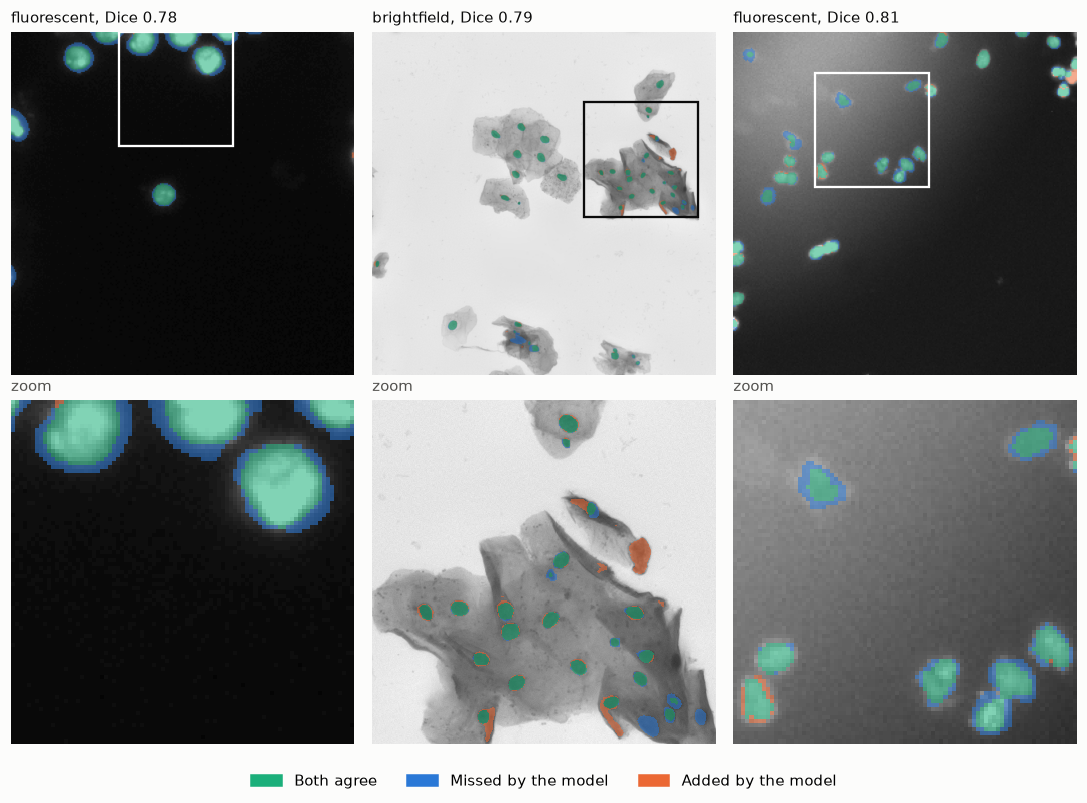

In [14]:
from matplotlib.patches import Rectangle


def error_view(image, pred, truth):
    out = image.astype(np.float32).copy()
    for region, color in ((pred & truth, AQUA), (truth & ~pred, BLUE), (pred & ~truth, ORANGE)):
        out[region] = 0.45 * out[region] + 0.55 * np.array(rgb_of(color), np.float32)
    return out.astype(np.uint8)


def busiest_square(errors, size):
    # Top-left corner of the square window holding the most disagreement pixels.
    h, w = errors.shape
    size = min(size, h, w)
    total = cv2.integral(errors.astype(np.uint8))
    best, corner, step = -1, (0, 0), max(size // 8, 1)
    for y in range(0, h - size + 1, step):
        for x in range(0, w - size + 1, step):
            count = total[y + size, x + size] - total[y, x + size] - total[y + size, x] + total[y, x]
            if count > best:
                best, corner = count, (y, x)
    return corner, size


worst = scores.nsmallest(3, "dice")
fig, axes = plt.subplots(2, 3, figsize=(10, 7.2))
for col, (_, row) in enumerate(worst.iterrows()):
    i = row["id"]
    pred, truth = probs[i] > THRESHOLD, binary[i]
    view = error_view(for_display(images[i]), pred, truth)
    (y, x), size = busiest_square(pred ^ truth, max(64, min(truth.shape) // 3))
    frame = "#ffffff" if images[i].mean() < 100 else INK
    axes[0, col].imshow(view)
    axes[0, col].add_patch(Rectangle((x, y), size, size, fill=False, edgecolor=frame, linewidth=1.5))
    axes[0, col].set_title(f"{row['type']}, Dice {row['dice']:.2f}")
    axes[1, col].imshow(view[y:y + size, x:x + size], interpolation="nearest")
    axes[1, col].set_title("zoom", color=INK2)
for ax in axes.ravel():
    ax.axis("off")
fig.legend(handles=[Patch(color=AQUA, label="Both agree"),
                    Patch(color=BLUE, label="Missed by the model"),
                    Patch(color=ORANGE, label="Added by the model")],
           loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.05, 1, 1), h_pad=2)
plt.show()

**Counting.** Touching nuclei merge into one blob in a mask, so before counting I split them with a watershed on the distance to the blob edge (`split_nuclei` in `inference.py`). Here the model's count is compared with the hand count on every test image.

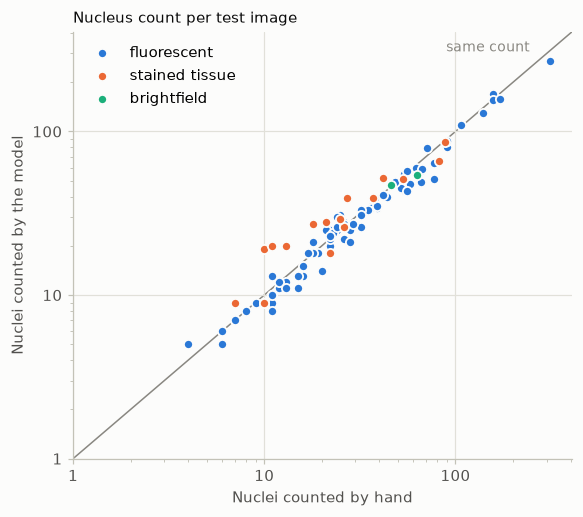

,test_images,median_count_error_pct,pct_images_within_10pct
type,,,
fluorescent,82,9.1,56.1
stained tissue,16,21.7,31.2
brightfield,2,8.2,50.0


In [15]:
counts = pd.DataFrame([{"id": i, "type": type_of[i], "by_hand": int(nuclei_of[i]),
                        "model": split_nuclei(probs[i] > THRESHOLD)[1]} for i in test_ids])
counts["error_pct"] = 100 * (counts.model - counts.by_hand).abs() / counts.by_hand

fig, ax = plt.subplots(figsize=(5.4, 4.8))
top = max(counts.by_hand.max(), counts.model.max()) * 1.3
ax.plot([1, top], [1, top], color=MUTED, linewidth=1, zorder=1)
ax.annotate("same count", (top / 1.5, top / 1.5), xytext=(-6, 6), textcoords="offset points",
            color=MUTED, ha="right", fontsize=9)
for t in TYPES:
    c = counts[counts.type == t]
    ax.scatter(c.by_hand, c.model, s=36, color=TYPE_COLORS[t], edgecolor=SURFACE, linewidth=1.2, label=t, zorder=2)
ax.set(xscale="log", yscale="log", xlim=(1, top), ylim=(1, top),
       xlabel="Nuclei counted by hand", ylabel="Nuclei counted by the model")
plain = FuncFormatter(lambda value, _: f"{value:g}")
ax.xaxis.set_major_formatter(plain)
ax.yaxis.set_major_formatter(plain)
ax.set_title("Nucleus count per test image")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

counts.groupby("type").agg(test_images=("id", "size"),
                           median_count_error_pct=("error_pct", "median"),
                           pct_images_within_10pct=("error_pct", lambda e: 100 * (e <= 10).mean())).reindex(TYPES).round(1)

## 5. Label check after training

The trained model now gives a second opinion on the training labels. When it finds a clear nucleus that has no mask at all, the label is often what is missing. These images go to a person for review. Nothing is changed automatically.

In [16]:
area_median = masks_df.groupby("id").area.median()
split_of = meta.set_index("id").split
review_rows, missed_masks = [], {}
for i in train_ids + val_ids:
    prob = probs[i] if i in probs else predict(model, images[i])
    blobs, _ = ndi.label(prob > THRESHOLD)
    min_area = max(30, 0.3 * area_median[i])
    missed = np.zeros(blobs.shape, bool)
    for k, box in enumerate(ndi.find_objects(blobs), start=1):
        region = blobs[box] == k
        area = region.sum()
        if area >= min_area and (region & binary[i][box]).sum() < 0.1 * area and prob[box][region].mean() > 0.8:
            missed[box] |= region
    missed_masks[i] = missed
    review_rows.append({"id": i, "split": split_of[i], "type": type_of[i],
                        "possible_missed_nuclei": ndi.label(missed)[1]})
review = pd.DataFrame(review_rows).sort_values("possible_missed_nuclei", ascending=False)
review[review.possible_missed_nuclei > 0].to_csv("review_list.csv", index=False)
print(f"{(review.possible_missed_nuclei > 0).sum()} of {len(review)} training and validation images have at least "
      f"one clear nucleus with no mask ({review.possible_missed_nuclei.sum()} nuclei in total). Listed in review_list.csv.")

40 of 570 training and validation images have at least one clear nucleus with no mask (152 nuclei in total). Listed in review_list.csv.


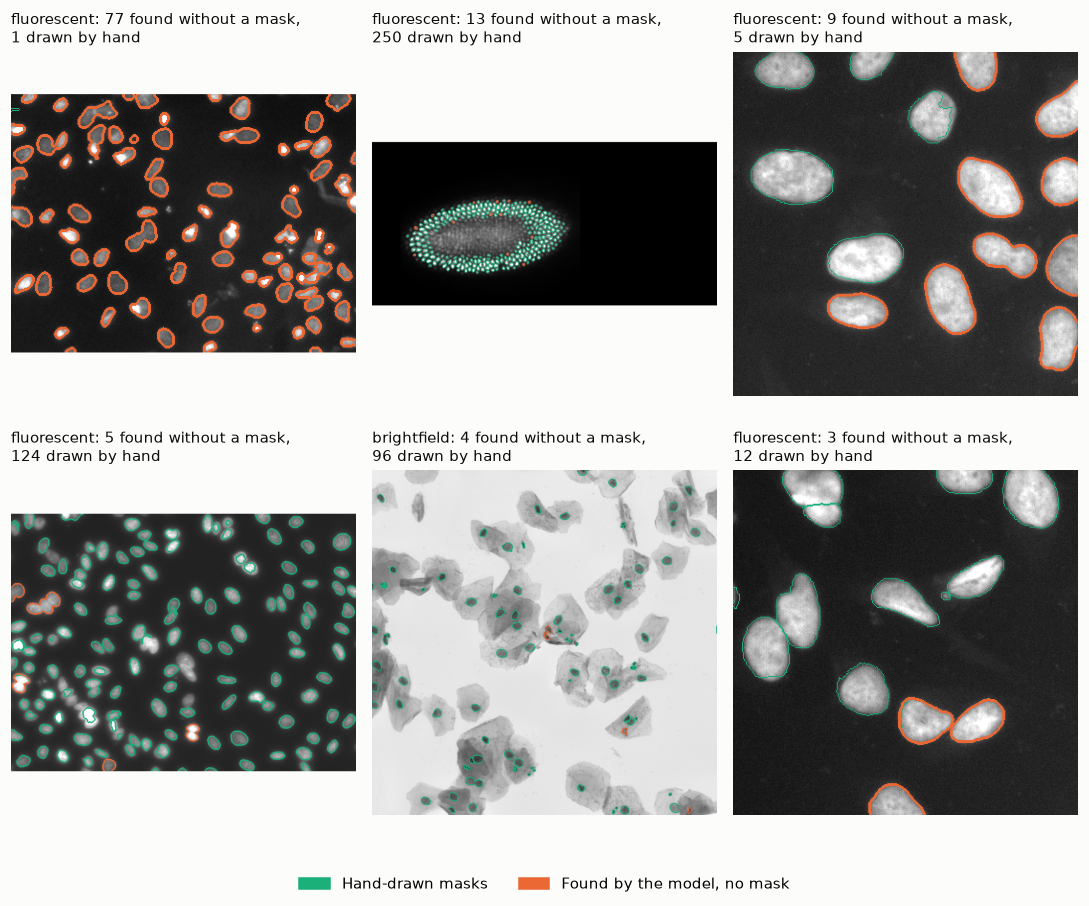

In [17]:
def pad_square(view):
    # Pad with the page color so every panel has the same shape and the titles line up.
    h, w = view.shape[:2]
    side = max(h, w)
    out = np.full((side, side, 3), rgb_of(SURFACE), np.uint8)
    out[(side - h) // 2:(side - h) // 2 + h, (side - w) // 2:(side - w) // 2 + w] = view
    return out


fig, axes = plt.subplots(2, 3, figsize=(10, 8.2))
for ax, (_, row) in zip(axes.ravel(), review.head(6).iterrows()):
    i = row["id"]
    view = draw_outlines(for_display(images[i]), label_maps[i], color=rgb_of(AQUA))
    view = draw_outlines(view, ndi.label(missed_masks[i])[0], color=rgb_of(ORANGE), thick=True)
    ax.imshow(pad_square(view))
    ax.set_title(f"{row['type']}: {row['possible_missed_nuclei']} found without a mask,\n{nuclei_of[i]} drawn by hand")
for ax in axes.ravel():
    ax.axis("off")
fig.legend(handles=[Patch(color=AQUA, label="Hand-drawn masks"),
                    Patch(color=ORANGE, label="Found by the model, no mask")], loc="lower center", ncol=2)
plt.tight_layout(rect=(0, 0.05, 1, 1), h_pad=3)
plt.show()

## 6. Optimization for deployment

A web server usually runs on a CPU, so I export the model to ONNX, check that it gives the same masks, and measure the speed. I also try an 8-bit version, which is four times smaller, and measure what it costs in accuracy.

In [18]:
import warnings

import onnxruntime as ort

cpu_model = new_model(pretrained=False)
cpu_model.load_state_dict(torch.load(MODELS / "unet_pretrained.pt", map_location="cpu"))
cpu_model.eval()

ONNX_PATH = MODELS / "nuclei_unet.onnx"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # the exporter warns that it is the older of two exporters
    torch.onnx.export(cpu_model, torch.zeros(1, 3, CROP, CROP), ONNX_PATH, input_names=["image"], output_names=["logits"],
                      dynamic_axes={"image": {0: "batch", 2: "height", 3: "width"},
                                    "logits": {0: "batch", 2: "height", 3: "width"}},
                      opset_version=17, dynamo=False)
session = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])

check_id = max(test_ids, key=lambda i: images[i].shape[0] * images[i].shape[1])  # the largest test image
x, _ = preprocess(images[check_id])
with torch.no_grad():
    torch_logits = cpu_model(torch.from_numpy(x)).numpy()
onnx_logits = session.run(None, {"image": x})[0]
cut = np.log(THRESHOLD / (1 - THRESHOLD))
print(f"Largest difference in the raw output: {np.abs(torch_logits - onnx_logits).max():.5f}")
print(f"Pixels with the same mask decision: {100 * ((torch_logits > cut) == (onnx_logits > cut)).mean():.3f}%")

Largest difference in the raw output: 0.00004
Pixels with the same mask decision: 100.000%


In [19]:
from onnxruntime.quantization import CalibrationDataReader, QuantFormat, QuantType, quantize_static
from onnxruntime.quantization.shape_inference import quant_pre_process


class TrainingCrops(CalibrationDataReader):
    # 32 random training crops show the quantizer the range of values the model meets.
    def __init__(self, n=32):
        rng = np.random.default_rng(SEED)
        self.batches = iter([{"image": random_crop(i, rng)[0][None]} for i in rng.choice(train_ids, n, replace=False)])

    def get_next(self):
        return next(self.batches, None)


PREPARED_PATH, INT8_PATH = MODELS / "nuclei_unet_prepared.onnx", MODELS / "nuclei_unet_int8.onnx"
quant_pre_process(str(ONNX_PATH), str(PREPARED_PATH))
quantize_static(str(PREPARED_PATH), str(INT8_PATH), TrainingCrops(), quant_format=QuantFormat.QDQ,
                activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8, per_channel=True)
session_int8 = ort.InferenceSession(str(INT8_PATH), providers=["CPUExecutionProvider"])
print("8-bit model written")

8-bit model written


In [20]:
def median_ms(run, repeats=15):
    for _ in range(3):
        run()
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        run()
        times.append(time.perf_counter() - t0)
    return 1000 * float(np.median(times))


def test_dice(prob_fn):
    return float(np.mean([dice(prob_fn(images[i]) > THRESHOLD, binary[i]) for i in test_ids]))


speed_id = next(i for i in test_ids if min(images[i].shape[:2]) >= 512)
x512, _ = preprocess(np.ascontiguousarray(images[speed_id][:512, :512]))
size_mb = lambda path: os.path.getsize(path) / 1e6
with torch.no_grad():
    torch_ms = median_ms(lambda: cpu_model(torch.from_numpy(x512)))
speed = pd.DataFrame([
    {"version": "PyTorch, 32-bit", "file_size_mb": size_mb(MODELS / "unet_pretrained.pt"),
     "cpu_ms_per_512px_image": torch_ms, "test_dice": scores.dice.mean()},
    {"version": "ONNX Runtime, 32-bit", "file_size_mb": size_mb(ONNX_PATH),
     "cpu_ms_per_512px_image": median_ms(lambda: session.run(None, {"image": x512})),
     "test_dice": test_dice(lambda im: predict_prob_onnx(session, im))},
    {"version": "ONNX Runtime, 8-bit", "file_size_mb": size_mb(INT8_PATH),
     "cpu_ms_per_512px_image": median_ms(lambda: session_int8.run(None, {"image": x512})),
     "test_dice": test_dice(lambda im: predict_prob_onnx(session_int8, im))},
]).set_index("version")
speed.round({"file_size_mb": 1, "cpu_ms_per_512px_image": 0, "test_dice": 3})

,file_size_mb,cpu_ms_per_512px_image,test_dice
version,,,
"PyTorch, 32-bit",97.9,199.0,0.920
"ONNX Runtime, 32-bit",97.7,82.0,0.920
"ONNX Runtime, 8-bit",24.7,65.0,0.917


## 7. Web-based inference

A small web app on top of the ONNX model: upload a microscope image, and the app outlines each nucleus and counts them. The same app is also an API, so a web platform can call it directly ("Use via API" at the bottom of the app page).

In [21]:
import gradio as gr

EXAMPLES = Path("examples")
EXAMPLES.mkdir(exist_ok=True)
example_files = []
for t in TYPES:
    of_type = scores[scores.type == t].sort_values("dice")
    pick = of_type.id.iloc[len(of_type) // 2]  # a typical test image of each type
    path = EXAMPLES / f"{t.replace(' ', '_')}.png"
    cv2.imwrite(str(path), images[pick][..., ::-1])
    example_files.append(str(path))


def segment(image):
    nuclei, count = split_nuclei(predict_prob_onnx(session, image) > THRESHOLD)
    return draw_nuclei(image, nuclei, color=rgb_of(ORANGE)), f"{count} nuclei"


app = gr.Interface(
    fn=segment,
    inputs=gr.Image(type="numpy", label="Microscope image"),
    outputs=[gr.Image(label="Nuclei found by the model"), gr.Textbox(label="Count")],
    examples=example_files,
    title="Nuclei segmentation",
    description="Upload a microscope image. The model outlines each nucleus and counts them, running the ONNX model on the CPU.",
    flagging_mode="never",
    api_name="segment",
)
app.launch(inline=False, share=False, prevent_thread_lock=True)
print("Open the app at", app.local_url)

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.
Open the app at http://127.0.0.1:7861/


In [22]:
from gradio_client import Client, handle_file

client = Client(app.local_url, verbose=False)
outlined_image, count = client.predict(handle_file(example_files[0]), api_name="/segment")
print("API answer for", Path(example_files[0]).name, "->", count)

API answer for fluorescent.png -> 35 nuclei


For a platform with its own front end, `serve.py` puts the same model behind a plain REST endpoint (FastAPI):

```
uvicorn serve:app --port 8000
curl -F "file=@examples/fluorescent.png" http://127.0.0.1:8000/segment
```

It returns the count and the mask as a PNG.

## Summary

In [23]:
pd.DataFrame([
    ("Test Dice, all test images", f"{scores.dice.mean():.3f}"),
    *[(f"Test Dice, {t}", f"{results.loc[t, 'mean_dice']:.3f}") for t in TYPES],
    ("Nucleus count, median error on test images", f"{counts.error_pct.median():.1f}%"),
    ("Masks flagged before training", f"{len(flagged)} in {flagged.id.nunique()} images"),
    ("Images with possible missed nuclei, after training", f"{(review.possible_missed_nuclei > 0).sum()}"),
    ("CPU time per 512 x 512 image, ONNX", f"{speed.loc['ONNX Runtime, 32-bit', 'cpu_ms_per_512px_image']:.0f} ms"),
    ("8-bit model", f"{speed.loc['ONNX Runtime, 8-bit', 'file_size_mb']:.0f} MB, test Dice {speed.loc['ONNX Runtime, 8-bit', 'test_dice']:.3f}"),
], columns=["", "result"]).set_index("")

,result
,
"Test Dice, all test images",0.920
"Test Dice, fluorescent",0.927
"Test Dice, stained tissue",0.894
"Test Dice, brightfield",0.839
"Nucleus count, median error on test images",10.0%
Masks flagged before training,45 in 22 images
"Images with possible missed nuclei, after training",40
"CPU time per 512 x 512 image, ONNX",82 ms
8-bit model,"25 MB, test Dice 0.917"


### With real project data

1. Split by source (slide, patient or session) rather than by image, so the test score reflects new data.
2. Run the label checks from sections 2 and 5 on the existing annotations before training.
3. Compare two or three architectures on the same split. U-Net, DeepLabV3+ and SegFormer are one line each in the library used here.
4. Serve the ONNX model behind an API next to the platform that uses it, in a Docker container.